In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# ==============================================================
# CASE 3: CLUSTERING
# K-MEANS + DBSCAN
# ==============================================================

In [2]:
df=pd.read_csv("pha_dataset_cleaned.csv")
               

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9388\2085802402.py:1: DtypeWarning: Columns (0: pdes, 1: name, 2: prefix) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("pha_dataset_cleaned.csv")


In [3]:
df.head(4)

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980


==========================================
CASE 3: ASTEROID CLUSTERING
==========================================


In [4]:
# 1. SELECT ORBITAL FEATURES
# --------------------------------------------------------------

orbital_cols = ["a", "e", "i", "q", "ad", "n"]

df_cluster = df.dropna(subset=orbital_cols).copy()

# Physical filter
df_cluster = df_cluster[
    (df_cluster["e"] >= 0) &
    (df_cluster["e"] < 1)].copy()

X = df_cluster[orbital_cols]

In [5]:
# 2. SCALE
# --------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X_scaled.shape)

Dataset shape: (958520, 6)


In [6]:
# 3. TAKE SAMPLE FOR CLUSTERING OPTIMIZATION
# --------------------------------------------------------------

sample_size = min(10000, len(X_scaled))

np.random.seed(42)

sample_indices = np.random.choice(len(X_scaled),size=sample_size,replace=False)

X_sample = X_scaled[sample_indices]

print("Optimization sample:", X_sample.shape)

Optimization sample: (10000, 6)


In [7]:
# K-MEANS OPTIMIZATION
# ==============================================================

k_range = range(2, 9)

inertias = []
kmeans_silhouette_scores = []

for k in k_range:

    print(f"Running K-Means k={k}...")

    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10 )

    labels = kmeans.fit_predict(X_sample)

    # Inertia
    inertias.append(kmeans.inertia_)

    # Silhouette
    silhouette = silhouette_score(X_sample,labels)

    kmeans_silhouette_scores.append(silhouette)

    print(f"k = {k} | "f"Inertia = {kmeans.inertia_:.2f} | "f"Silhouette = {silhouette:.4f}")

Running K-Means k=2...
k = 2 | Inertia = 31411.05 | Silhouette = 0.3634
Running K-Means k=3...
k = 3 | Inertia = 22447.28 | Silhouette = 0.3742
Running K-Means k=4...
k = 4 | Inertia = 17777.75 | Silhouette = 0.3274
Running K-Means k=5...
k = 5 | Inertia = 14596.67 | Silhouette = 0.2776
Running K-Means k=6...
k = 6 | Inertia = 12298.96 | Silhouette = 0.2908
Running K-Means k=7...
k = 7 | Inertia = 10681.26 | Silhouette = 0.3049
Running K-Means k=8...
k = 8 | Inertia = 9475.15 | Silhouette = 0.2851


In [8]:
# Best k
best_k = list(k_range)[np.argmax(kmeans_silhouette_scores)]

best_k_silhouette = max(kmeans_silhouette_scores)

print("\n[SELECTION]")
print("Best k =", best_k)
print("Best Silhouette =",round(best_k_silhouette, 4))



[SELECTION]
Best k = 3
Best Silhouette = 0.3742


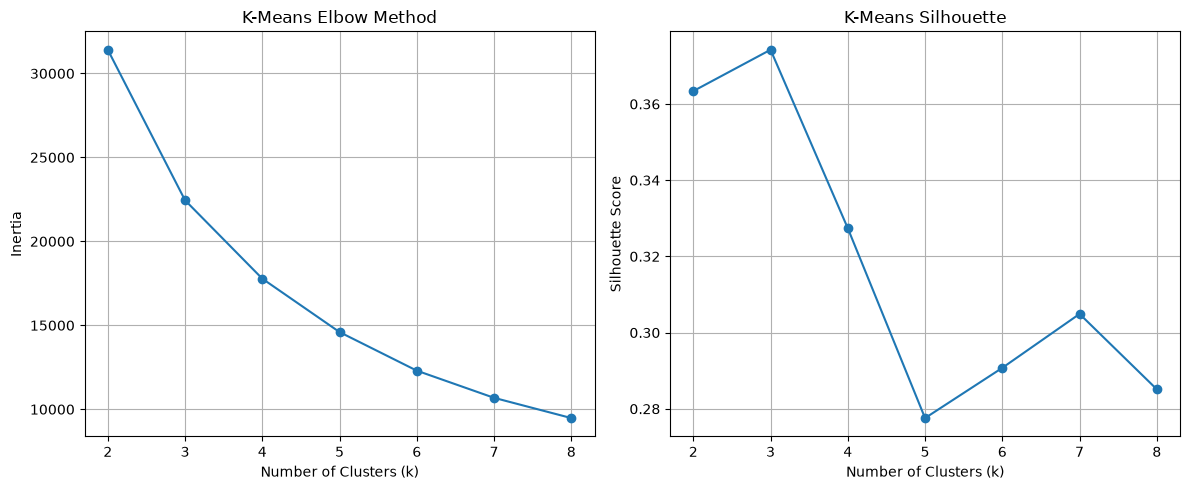

In [9]:
# ELBOW + SILHOUETTE PLOTS
# ==============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(list(k_range),inertias,marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.grid(True)


plt.subplot(1, 2, 2)
plt.plot(list(k_range),kmeans_silhouette_scores,marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette")
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# FINAL K-MEANS
# ==============================================================
# Fit final K-Means on FULL dataset

print("\nRunning final K-Means on full dataset...")

kmeans_final = KMeans(n_clusters=best_k,random_state=42,n_init=10)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

df_cluster["kmeans_cluster"] = kmeans_labels

print("Final K-Means completed.")


Running final K-Means on full dataset...
Final K-Means completed.


# ==============================================================
# DBSCAN TUNING
# ==============================================================


In [11]:
# min_samples
min_samples_values = [5, 10, 15]

# eps values
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7]

dbscan_results = []


for min_samples in min_samples_values:

    print(f"\nTesting min_samples = {min_samples}"    )

    for eps in eps_values:

        print(f"  Testing eps = {eps}..."        )

        dbscan = DBSCAN(eps=eps,min_samples=min_samples ,n_jobs=-1  )
        labels = dbscan.fit_predict(X_sample)

        # Number of clusters excluding noise
        unique_labels = set(labels)

        n_clusters = len(unique_labels - {-1})

        # Noise count
        n_noise = np.sum(labels == -1  )

        # Silhouette
        non_noise = labels != -1

        if (n_clusters >= 2 and non_noise.sum() > n_clusters ):

            silhouette = silhouette_score(
                X_sample[non_noise],
                labels[non_noise] )

        else:

            silhouette = -1


        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise": n_noise,
            "silhouette": silhouette })

        print(
            f"    clusters={n_clusters} | "
            f"noise={n_noise} | "
            f"silhouette={silhouette:.4f}")




Testing min_samples = 5
  Testing eps = 0.3...
    clusters=17 | noise=548 | silhouette=0.0398
  Testing eps = 0.4...
    clusters=8 | noise=384 | silhouette=0.1750
  Testing eps = 0.5...
    clusters=8 | noise=295 | silhouette=0.3382
  Testing eps = 0.6...
    clusters=6 | noise=233 | silhouette=0.3835
  Testing eps = 0.7...
    clusters=6 | noise=178 | silhouette=0.3864

Testing min_samples = 10
  Testing eps = 0.3...
    clusters=6 | noise=727 | silhouette=0.3468
  Testing eps = 0.4...
    clusters=7 | noise=517 | silhouette=0.1246
  Testing eps = 0.5...
    clusters=3 | noise=410 | silhouette=0.3598
  Testing eps = 0.6...
    clusters=5 | noise=318 | silhouette=0.3451
  Testing eps = 0.7...
    clusters=2 | noise=255 | silhouette=0.4008

Testing min_samples = 15
  Testing eps = 0.3...
    clusters=6 | noise=814 | silhouette=0.3555
  Testing eps = 0.4...
    clusters=4 | noise=651 | silhouette=0.3276
  Testing eps = 0.5...
    clusters=4 | noise=482 | silhouette=0.3482
  Testing ep

In [12]:
# DBSCAN BEST PARAMETERS
# ==============================================================

dbscan_results_df = pd.DataFrame(dbscan_results)

valid_results = dbscan_results_df[dbscan_results_df["silhouette"] >= 0]

if len(valid_results) > 0:

    best_dbscan_row = valid_results.loc[
        valid_results["silhouette"].idxmax() ]

    best_eps = best_dbscan_row["eps"]
    best_min_samples = int(best_dbscan_row["min_samples"])

else:
    best_eps = 0.5
    best_min_samples = 10


print("\n[DBSCAN SELECTION]")
print("Best eps =", best_eps)
print("Best min_samples =", best_min_samples)

print("Best DBSCAN Silhouette =",round(best_dbscan_row["silhouette"],4 )
    if len(valid_results) > 0
    else "Not available")


[DBSCAN SELECTION]
Best eps = 0.7
Best min_samples = 10
Best DBSCAN Silhouette = 0.4008


In [13]:
# FINAL DBSCAN
# ==============================================================

print("\nRunning final DBSCAN on optimization sample...")

dbscan_final = DBSCAN(eps=best_eps,min_samples=best_min_samples,n_jobs=-1)

dbscan_labels = dbscan_final.fit_predict(X_sample)

# Final DBSCAN silhouette
non_noise = dbscan_labels != -1

n_clusters_dbscan = len(set(dbscan_labels) - {-1})

if (n_clusters_dbscan >= 2 and non_noise.sum() > n_clusters_dbscan):

    final_dbscan_silhouette = silhouette_score(X_sample[non_noise],dbscan_labels[non_noise] )

else:
    final_dbscan_silhouette = -1


print("Final DBSCAN clusters =", n_clusters_dbscan)

print("Final DBSCAN noise points =", np.sum(dbscan_labels == -1))



Running final DBSCAN on optimization sample...
Final DBSCAN clusters = 2
Final DBSCAN noise points = 255


In [14]:
# MODEL COMPARISON
# ==============================================================

print("\n==========================================")
print("MODEL COMPARISON")
print("==========================================")

print( f"K-Means  | k={best_k} | " f"Silhouette={best_k_silhouette:.4f}")

print(f"DBSCAN   | eps={best_eps} | " f"min_samples={best_min_samples} | " 
        f"Silhouette={final_dbscan_silhouette:.4f}")


MODEL COMPARISON
K-Means  | k=3 | Silhouette=0.3742
DBSCAN   | eps=0.7 | min_samples=10 | Silhouette=0.4008


# ==============================================================
# SAVE DBSCAN TUNING RESULTS
# ==============================================================

In [15]:
import os

os.makedirs("results", exist_ok=True)

dbscan_results_df.to_csv("results/case3_dbscan_tuning.csv",index=False)

print("\n[SAVED] DBSCAN tuning results saved.")


[SAVED] DBSCAN tuning results saved.
